1. Load the data (pipe-separated files)
2. Batch duration and downtime
3. Join and checks

In [5]:
import pandas as pd, glob

prod  = pd.read_csv("line-productivity.csv", sep="|")
fact  = pd.read_csv("downtime-factors.csv", sep="|")
prods = pd.read_csv("products.csv", sep="|")

# downtime: drop the extra header row, rename columns to factor IDs 1..12
down = pd.read_csv("line-downtime.csv", sep="|").iloc[1:].copy()
down.columns = ["Batch"] + list(range(1, 13))
down["Batch"] = pd.to_numeric(down["Batch"], errors="coerce")
down = down.dropna(subset=["Batch"])
down["Batch"] = down["Batch"].astype(int)
down[list(range(1, 13))] = down[list(range(1, 13))].apply(pd.to_numeric, errors="coerce")

print("prod", prod.shape, "| down", down.shape, "| fact", fact.shape, "| prods", prods.shape)
print(prod.dtypes, "\n")
print(down.head(), "\n")
print("Batches in prod but not in down:", sorted(set(prod.Batch) - set(down.Batch)))
print("Batches in down but not in prod:", sorted(set(down.Batch) - set(prod.Batch)))
print("Duplicate batch IDs in prod:", prod.Batch.duplicated().sum())
print(fact)
print(prods)

# 1. clean times: keep only HH:MM:SS (some cells carry a stray "1900-01-01")
t_start = prod["Start Time"].astype(str).str.extract(r"(\d{1,2}:\d{2}:\d{2})")[0]
t_end   = prod["End Time"].astype(str).str.extract(r"(\d{1,2}:\d{2}:\d{2})")[0]
print("Unparsed times:", t_start.isna().sum(), t_end.isna().sum())

start = pd.to_datetime(prod["Date"] + " " + t_start)
end   = pd.to_datetime(prod["Date"] + " " + t_end)
end   = end.where(end >= start, end + pd.Timedelta(days=1))   # crossed midnight
prod["BatchMinutes"] = (end - start).dt.total_seconds() / 60

# 2. total downtime per batch (NaN = no downtime logged)
down["DowntimeMinutes"] = down[list(range(1, 13))].sum(axis=1)

# 3. join: keep only batches that exist in production (drops the 7 orphans)
df = (prod.merge(prods, on="Product", how="left")
          .merge(down[["Batch", "DowntimeMinutes"]], on="Batch", how="left"))
df["RunMinutes"] = df["BatchMinutes"] - df["DowntimeMinutes"]
df["RunVsMin"]   = df["RunMinutes"] - df["Min batch time"]

print(df.shape)
print(df[["Batch", "Product", "Start Time", "End Time", "BatchMinutes",
          "DowntimeMinutes", "RunMinutes", "Min batch time", "RunVsMin"]].to_string())
print("\nRunVsMin summary:\n", df["RunVsMin"].describe())
print("\nNull check:\n", df[["BatchMinutes", "DowntimeMinutes", "Min batch time"]].isna().sum())

prod (31, 6) | down (38, 13) | fact (12, 3) | prods (5, 4)
Date          object
Product       object
Batch          int64
Operator      object
Start Time    object
End Time      object
dtype: object 

    Batch   1     2   3     4   5     6     7     8   9    10  11  12
1  422111 NaN  60.0 NaN   NaN NaN   NaN  15.0   NaN NaN   NaN NaN NaN
2  422112 NaN  20.0 NaN   NaN NaN   NaN   NaN  20.0 NaN   NaN NaN NaN
3  422113 NaN  50.0 NaN   NaN NaN   NaN   NaN   NaN NaN   NaN NaN NaN
4  422114 NaN   NaN NaN  25.0 NaN  15.0   NaN   NaN NaN   NaN NaN NaN
5  422115 NaN   NaN NaN   NaN NaN   NaN   NaN   NaN NaN  24.0 NaN NaN 

Batches in prod but not in down: []
Batches in down but not in prod: [422137, 422138, 422139, 422140, 422141, 422142, 422143]
Duplicate batch IDs in prod: 0
    Factor         Description Operator Error
0        1      Emergency stop             No
1        2        Batch change            Yes
2        3      Labeling error             No
3        4  Inventory shortage      

4. Availability, Pareto, operator split

In [7]:
# Availability per batch (Performance is always 100% here, so OEE = Availability)
df["Availability"] = df["Min batch time"] / df["BatchMinutes"]

# Downtime in long form: use ONLY Batch + the 12 factor columns
factor_cols = list(range(1, 13))
long = down[["Batch"] + factor_cols].melt(id_vars="Batch", var_name="Factor",
                                          value_name="DowntimeMinutes")
long = long.dropna(subset=["DowntimeMinutes"])
long = long[long["DowntimeMinutes"] > 0]
long = long[long["Batch"].isin(df["Batch"])].merge(fact, on="Factor", how="left")

# Sanity check: both totals must match
print("Downtime total (long) :", long["DowntimeMinutes"].sum())
print("Downtime total (batch):", df["DowntimeMinutes"].sum())
print("Factors with no description match:", long["Description"].isna().sum())

# Overall availability (time-weighted) and per-batch spread
print(f"\nPlant Availability: {df['Min batch time'].sum() / df['BatchMinutes'].sum():.1%}")
print(df["Availability"].describe().round(3))

# Pareto
pareto = long.groupby("Description")["DowntimeMinutes"].sum().sort_values(ascending=False)
cum = (pareto.cumsum() / pareto.sum() * 100).round(1)
print("\nPareto:\n", pd.DataFrame({"minutes": pareto, "cum_%": cum}))
print("Causes needed to reach 80%:", (cum < 80).sum() + 1, "of", len(pareto))

# Operator-attributable vs equipment
split = long.groupby("Operator Error")["DowntimeMinutes"].sum()
print("\nOperator-error split:\n", split, "\n", (split / split.sum() * 100).round(1))

# Availability by product
by_prod = df.groupby("Product").agg(Batches=("Batch", "count"),
                                    BatchMin=("BatchMinutes", "sum"),
                                    MinTime=("Min batch time", "sum"))
by_prod["Availability"] = (by_prod["MinTime"] / by_prod["BatchMin"]).round(3)
print("\nBy product:\n", by_prod)

Downtime total (long) : 1130.0
Downtime total (batch): 1130.0
Factors with no description match: 0

Plant Availability: 64.5%
count    31.000
mean      0.677
std       0.153
min       0.444
25%       0.558
50%       0.667
75%       0.752
max       1.000
Name: Availability, dtype: float64

Pareto:
                     minutes  cum_%
Description                       
Machine failure       236.0   20.9
Inventory shortage    205.0   39.0
Machine adjustment    197.0   56.5
Batch change          160.0   70.6
Batch coding error    115.0   80.8
Other                  67.0   86.7
Product spill          57.0   91.8
Calibration error      34.0   94.8
Labeling error         22.0   96.7
Label switch           20.0   98.5
Conveyor belt jam      17.0  100.0
Causes needed to reach 80%: 5 of 11

Operator-error split:
 Operator Error
No     547.0
Yes    583.0
Name: DowntimeMinutes, dtype: float64 
 Operator Error
No     48.4
Yes    51.6
Name: DowntimeMinutes, dtype: float64

By product:
          Batch

5. Charts and exports

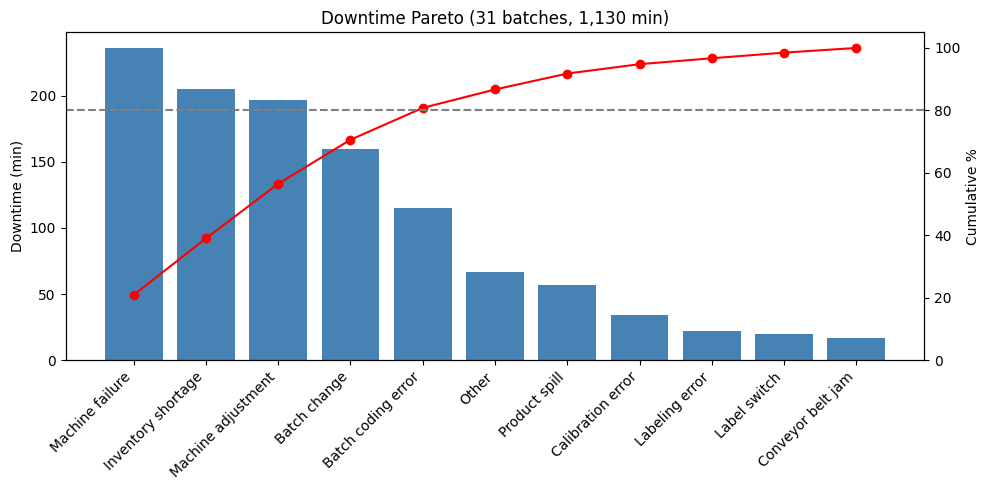

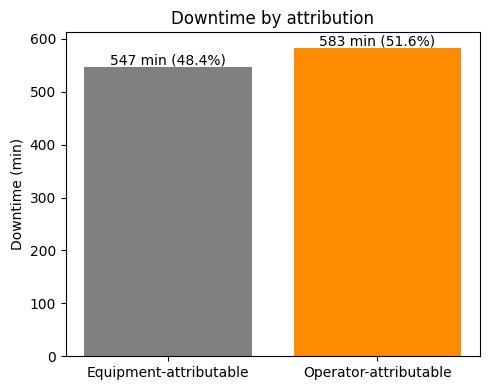

            BatchMin  MinTime  Availability
Date                                       
2024-08-29     664.0      420         0.633
2024-08-30    1164.0      720         0.619
2024-08-31     585.0      420         0.718
2024-09-02     637.0      392         0.615
2024-09-03     130.0       98         0.754


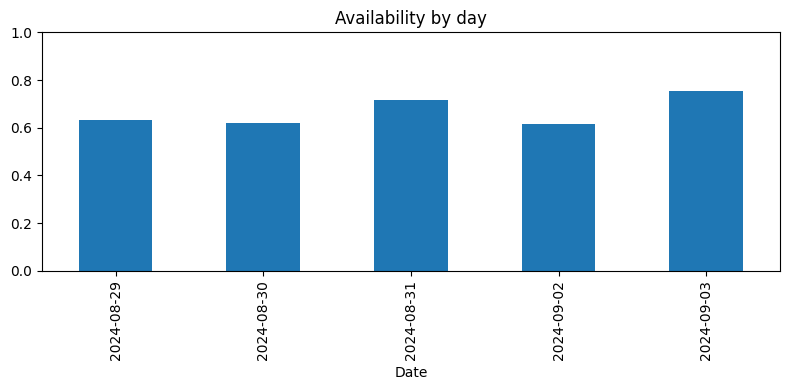

Saved: pareto.png, operator_split.png, daily_availability.png, batches_clean.csv, downtime_long.csv


In [8]:
import matplotlib.pyplot as plt

# 1. Pareto chart
x = range(len(pareto))
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(x, pareto.values, color="steelblue")
ax1.set_xticks(list(x)); ax1.set_xticklabels(pareto.index, rotation=45, ha="right")
ax1.set_ylabel("Downtime (min)")
ax2 = ax1.twinx()
ax2.plot(x, cum.values, color="red", marker="o")
ax2.axhline(80, ls="--", color="grey")
ax2.set_ylim(0, 105); ax2.set_ylabel("Cumulative %")
plt.title("Downtime Pareto (31 batches, 1,130 min)")
plt.tight_layout(); plt.savefig("pareto.png", dpi=150); plt.show()

# 2. Operator vs equipment
fig, ax = plt.subplots(figsize=(5, 4))
labels = ["Equipment-attributable", "Operator-attributable"]
ax.bar(labels, [split["No"], split["Yes"]], color=["grey", "darkorange"])
for i, v in enumerate([split["No"], split["Yes"]]):
    ax.text(i, v + 5, f"{v:.0f} min ({v/split.sum():.1%})", ha="center")
ax.set_ylabel("Downtime (min)"); plt.title("Downtime by attribution")
plt.tight_layout(); plt.savefig("operator_split.png", dpi=150); plt.show()

# 3. Availability by day
d = df.groupby("Date").agg(BatchMin=("BatchMinutes", "sum"), MinTime=("Min batch time", "sum"))
d["Availability"] = d["MinTime"] / d["BatchMin"]
print(d.round(3))
d["Availability"].plot(kind="bar", figsize=(8, 4), title="Availability by day", ylim=(0, 1))
plt.tight_layout(); plt.savefig("daily_availability.png", dpi=150); plt.show()

# 4. Exports for Power BI
df.to_csv("batches_clean.csv", index=False)
long.to_csv("downtime_long.csv", index=False)
print("Saved: pareto.png, operator_split.png, daily_availability.png, batches_clean.csv, downtime_long.csv")